In [2]:
import json
with open("../../outputs/hpo/fixed_hpo/outputs.json", "r") as f:
    hpo_data = json.load(f)
with open("../../hpo/baseline_metrics.json", "r") as f:
    baseline_metrics = json.load(f)
print(baseline_metrics)

{'promoter_no_tata': {'mean': 0.7420857209666549, 'std': 0.00825544239869875, 'metric': 'val/mcc'}, 'H4K20me1': {'mean': 0.546681667447458, 'std': 0.01317334487953775, 'metric': 'val/mcc'}, 'H3K4me2': {'mean': 0.473280844250837, 'std': 0.007468769533808587, 'metric': 'val/mcc'}, 'promoter_all': {'mean': 0.7169109532736063, 'std': 0.00477370143055105, 'metric': 'val/mcc'}, 'H3K4me1': {'mean': 0.4040404113460082, 'std': 0.009953884460596387, 'metric': 'val/mcc'}, 'enhancers': {'mean': 0.49312815098430535, 'std': 0.002702191337782939, 'metric': 'val/mcc'}, 'promoter_tata': {'mean': 0.7214279669067885, 'std': 0.009989613782587342, 'metric': 'val/mcc'}, 'splice_sites_acceptors': {'mean': 0.50843269451932, 'std': 0.011123823298570088, 'metric': 'val/mcc'}, 'H2AFZ': {'mean': 0.39972925202073895, 'std': 0.009192948926767518, 'metric': 'val/mcc'}, 'H3K4me3': {'mean': 0.6124106981152095, 'std': 0.0131705686625567, 'metric': 'val/mcc'}, 'H3K9ac': {'mean': 0.5034676193498381, 'std': 0.010911141644

In [3]:
trial_scores = {}
for trial in hpo_data.keys():
    trial_scores[trial] = {}

for dataset_name in ("nt_benchmark", "genomic_benchmark", "bend_benchmark", "chromatin_profile_prediction"):
    def get_tasks(trial):
        global dataset_name
        if dataset_name == "chromatin_profile_prediction":
            cpp = trial.get("chromatin_profile_prediction")
            if cpp is not None:
                return {"chromatin_profile_prediction": cpp}
            else:
                return None
        else:
            return trial.get(dataset_name)

    for trial in hpo_data.keys():
        tasks = get_tasks(hpo_data[trial])

        if tasks is not None:
            for name, val in tasks.items():
                if name == "pretraining": 
                    continue
                trial_scores[trial][name] = val[0][baseline_metrics[name]["metric"]]

In [4]:
# Cleanup
for trial_key in list(trial_scores.keys()):
    if len(trial_scores[trial_key]) != 30:
        del trial_scores[trial_key]
    else:
        trial_scores[int(trial_key)] = trial_scores[trial_key]
        del trial_scores[trial_key]

In [5]:
# Turn it into df
import pandas as pd
df = pd.DataFrame.from_dict(trial_scores, orient="index")
print(df.info())

<class 'pandas.core.frame.DataFrame'>
Index: 21 entries, 0 to 20
Data columns (total 30 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   splice_sites_acceptors            21 non-null     float64
 1   H3K27me3                          21 non-null     float64
 2   splice_sites_all                  21 non-null     float64
 3   H3K4me2                           21 non-null     float64
 4   H2AFZ                             21 non-null     float64
 5   H3K4me1                           21 non-null     float64
 6   H3K27ac                           21 non-null     float64
 7   H3K9me3                           21 non-null     float64
 8   H3K4me3                           21 non-null     float64
 9   enhancers_types                   21 non-null     float64
 10  promoter_all                      21 non-null     float64
 11  enhancers                         21 non-null     float64
 12  promoter_tata  

In [6]:
z_scores = df.apply(lambda col: (col - baseline_metrics[col.name]["mean"]) / baseline_metrics[col.name]["std"], axis=0)

In [7]:
records = (df == df.max()).sum(axis=1)
records_list = sorted(list(records), reverse=True)
print([*records_list]) # The sum of records_list is higher than 30 because when there's a tie, it gives a record to all the tied trials.

[5, 3, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 1, 1, 0, 0, 0, 0, 0, 0]


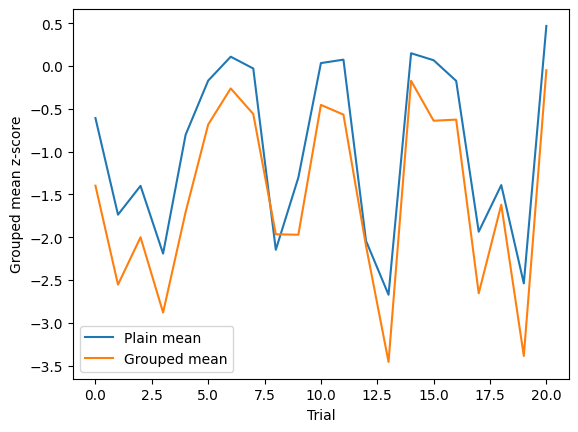

In [8]:
# Plot the grouped mean vs plain mean
from matplotlib import pyplot as plt

TASKS_GROUPS = {
    "histone": [
        "H2AFZ",
        "H3K27ac",
        "H3K27me3",
        "H3K36me3",
        "H3K4me1",
        "H3K4me2",
        "H3K4me3",
        "H3K9ac",
        "H3K9me3",
        "H4K20me1",
    ],
    "promoter": [
        "promoter_all",
        "promoter_tata",
        "promoter_no_tata",
        "human_nontata_promoters",
    ],
    "enhancers": [
        "enhancers",
        "enhancers_types",
        "dummy_mouse_enhancers_ensembl",
        "human_enhancers_cohn",
        "human_enhancers_ensembl",
        "human_ensembl_regulatory",
        "human_ocr_ensembl",
        "drosophila_enhancers_stark"
    ],
    "splicing": [
        "splice_sites_all",
        "splice_sites_donors",
        "splice_sites_acceptors",
    ],
    "general_genomic_content": [
        "demo_coding_vs_intergenomic_seqs",
        "demo_human_or_worm",
    ],
    "gene_finding": ["gene_finding"],
    "cpg_methylation": ["cpg_methylation"],
    "chromatin_profile_prediction": ["chromatin_profile_prediction"]
}

groups = [z_scores[TASKS_GROUPS[group]].mean(axis=1) for group in TASKS_GROUPS]
grouped_means = pd.concat(groups, axis=1).mean(axis=1) # The axis for pd.concat specifies the resulting series direction, I wanna concatenate the series as columns
z_scores["grouped_means"] = grouped_means
z_scores["plain_means"] = z_scores.mean(axis=1)

ax = z_scores[["plain_means", "grouped_means"]].plot(xlabel="Trial", ylabel="Grouped mean z-score")
ax.legend(["Plain mean", "Grouped mean"])
plt.savefig("./grouped_z_score.png", dpi=300)
plt.show()

In [14]:
from optuna.visualization import (
    plot_optimization_history,
    plot_param_importances,
)
import optuna

study = optuna.load_study(study_name="hpo", storage="sqlite:///../../outputs/hpo/fixed_hpo/optuna.db")
opt_history = plot_optimization_history(study)
opt_history.update_layout(
    title=None,                # quita el título
    width=700,                 # ancho en px
    height=350,                # alto en px (aspect ratio 2:1)
    margin=dict(l=50, r=20, t=10, b=40),   # márgenes chicos, sin el espacio del título
    font=dict(size=12),
)
opt_history.show()

param_importances = plot_param_importances(study)
param_importances.update_layout(
    title=None,                # quita el título
    width=700,                 # ancho en px
    height=350,                # alto en px (aspect ratio 2:1)
    margin=dict(l=50, r=20, t=10, b=40),   # márgenes chicos, sin el espacio del título
    font=dict(size=12),
)
param_importances.show()

print(study.best_params)
opt_history.write_image("./opt_history.png", scale=5)
param_importances.write_image("./param_importances.png", scale=5)

{'overlapping_segments_canonicalization': 'both_break', 'annotations_level': 2, 'include_cdjv_segments': 'false', 'include_pseudogenes': 'true', 'transformation': 'rc'}


In [42]:
df = study.trials_dataframe(attrs=("number", "value", "params", "state"))
print(df)

    number     value  params_annotations_level params_include_cdjv_segments  \
0        0 -1.081062                         3                         true   
1        1 -2.208698                         1                        false   
2        2 -1.738034                         1                        false   
3        3 -2.580276                         3                        false   
4        4 -1.504947                         1                         true   
5        5 -0.402678                         3                         true   
6        6 -0.038528                         2                         true   
7        7 -0.314197                         2                         true   
8        8 -1.742867                         2                         true   
9        9 -1.685233                         1                        false   
10      10 -0.207797                         2                         true   
11      11 -0.331588                         2      

[0.573305442841069, 0.5240339451476759, 0.35036603212659984, 0.4813396657858339, 0.4059752459614273, 0.41998731470845685, 0.45971264790703703, 0.3268083171020845, 0.6499607813873634, 0.45618471528245874, 0.7491429278577186, 0.4924756083956685, 0.747502359587777, 0.6024122655242585, 0.5258966537824687, 0.5799361521298216, 0.7524951791570091, 0.5300432617562323, 0.9662399888038635, 0.9371263980865479, 0.7335259914398193, 0.8016529083251953, 0.7472653985023499, 0.9685999751091003, 0.8838553428649902, 0.7883096933364868, 0.7361599802970886, 0.11686704406285109, 0.8993211984634399, 0.8112348318099976]
[0.5714789495514794, 0.5038823417951649, 0.34144565552272516, 0.45373671079759026, 0.39675049785592215, 0.4121905380834148, 0.43662553413423083, 0.3022015881860595, 0.6201634019323619, 0.45223723569357094, 0.717784499454963, 0.4924756083956685, 0.7216201669468449, 0.5999771720043222, 0.5171599630354808, 0.5632775793042123, 0.7451075401075394, 0.5039781270872496, 0.938759982585907, 0.9241753220

<Axes: >

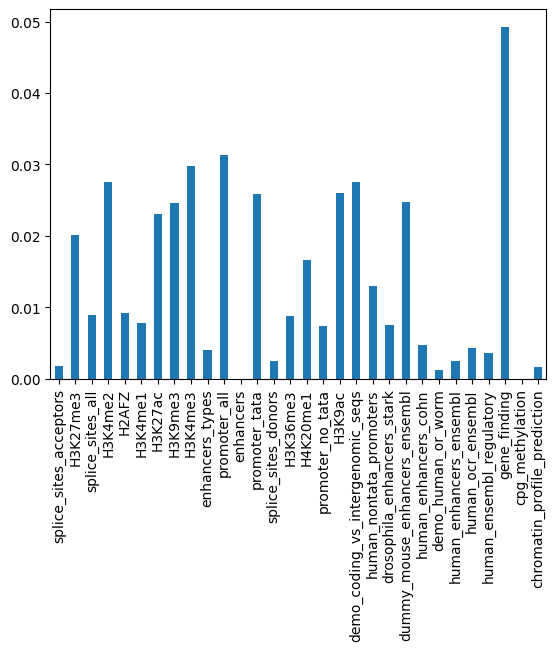

In [ ]:
# Check the generalist model vs each specialist model. This should be done with the repeated trials to get p-values
generalist = df.iloc[z_scores["grouped_means"].idxmax()]
specialists = df.max()
print(list(specialists))
print(list(generalist))

diffs = specialists - generalist
diffs.plot.bar()